# Problem 1 · Steady temperature distribution in an aluminium pin fin

**simple_CFD · Introduction to Computational Fluid Dynamics with the Finite Difference Method**

> *Determine the steady-state temperature distribution within an aluminium fin using the Finite Difference Method. The base of the fin is at 100 °C and its tip is insulated. Initially the fin is at 30 °C.*

In this notebook we solve the problem **step by step, following the 7 pillars of CFD**:

| Pillar | What we do here |
|:-:|---|
| 1 · Geometry | describe the fin and collect the data |
| 2 · Grid | divide the fin into small segments (nodes) |
| 3 · Physics | derive the fin equation from an energy balance |
| 4 · Numerical scheme | replace the derivative by a finite difference → one algebraic equation per node |
| 5 · Solution setup | choose two algorithms: Gauss–Seidel iteration and the Thomas algorithm |
| 6 · Compute | run them |
| 7 · Post-processing | plot, compare with the exact solution, compute the heat loss, check the grid |

> **Plain Python only.** All numerical work uses ordinary Python lists and `for` loops, so you can follow every number. The only import used in the calculations is `math` (part of Python itself), for square roots and `cosh` in the exact solution. The figures are drawn by `plots.py` (with matplotlib); you do not need to open it to follow the method.

In [1]:
import math     # built into Python: sqrt, cosh, tanh, pi
import plots    # our drawing helpers (plots.py)

---
## Pillar 1 · The physical problem and its geometry

A thin aluminium pin (a *fin*) sticks out of a hot wall. Heat **flows along the fin by conduction** and **leaves its surface by convection** to the surrounding air. Because the fin keeps losing heat along its length, it gets colder towards the tip. Fins like this are used to cool electronics, engines and heat exchangers.

The statement fixes the base temperature (100 °C), the tip condition (insulated) and the initial temperature (30 °C). The size of the fin, the material conductivity and the convection coefficient are not given, so we use **typical values** (change them in the cell below and re-run the notebook to explore):

| Quantity | Symbol | Value |
|---|:-:|---|
| fin length | $L$ | 10 cm |
| fin diameter | $d$ | 5 mm |
| thermal conductivity of aluminium | $k$ | 237 W/(m·K) |
| convection coefficient | $h$ | 25 W/(m²·K) |
| air temperature (= initial fin temperature) | $T_\infty$ | 30 °C |
| base temperature | $T_b$ | 100 °C |

**Assumptions:** steady state, one-dimensional conduction along $x$ (the fin is thin, so the temperature is uniform over each cross-section), constant $k$ and $h$, no radiation, insulated tip.

In [2]:
# ---- fin geometry -------------------------------------------------------
L = 0.10          # fin length                          [m]
d = 0.005         # fin diameter                        [m]

# ---- material and surroundings ------------------------------------------
k = 237.0         # thermal conductivity of aluminium   [W/(m K)]
h = 25.0          # convection heat transfer coefficient [W/(m^2 K)]
T_inf = 30.0      # temperature of the surrounding air  [°C]

# ---- boundary and initial conditions ------------------------------------
T_b = 100.0       # base temperature                    [°C]
T_init = 30.0     # initial temperature of the fin      [°C]

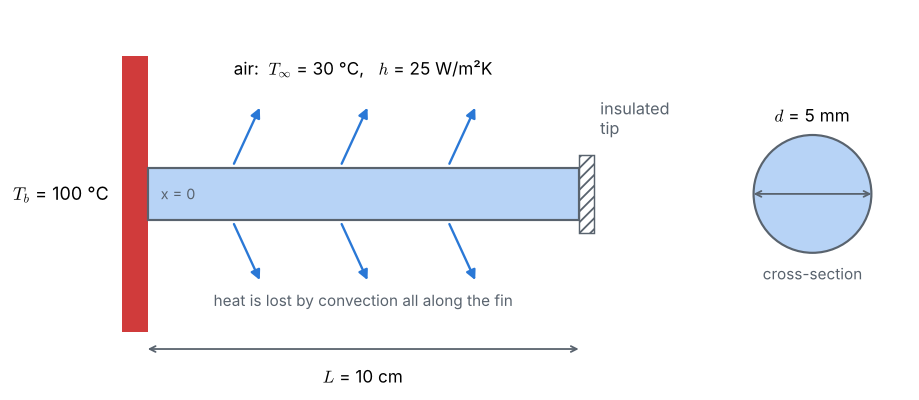

In [3]:
plots.schematic(L, d, T_b, T_inf, h)

Two geometric quantities of the circular cross-section appear in the equations: the **area** $A_c = \pi d^2/4$, through which heat is *conducted*, and the **perimeter** $P = \pi d$, through which heat is *convected* away.

In [4]:
A_c = math.pi * d**2 / 4      # cross-section area   [m^2]
P = math.pi * d               # perimeter            [m]

print(f"cross-section area  A_c = {A_c:.4e} m^2")
print(f"perimeter           P   = {P:.4e} m")

cross-section area  A_c = 1.9635e-05 m^2
perimeter           P   = 1.5708e-02 m


---
## Pillar 2 · The grid

A computer cannot store the temperature at the infinitely many points of the fin. We therefore keep only $N+1$ equally spaced points, the **nodes**:

$$x_i = i\,\Delta x, \qquad i = 0, 1, \dots, N, \qquad \Delta x = \frac{L}{N}.$$

Node $0$ is the base (temperature known), node $N$ is the tip (temperature unknown). We start with $N = 10$, i.e. one node every centimetre.

In [5]:
N = 10                    # number of intervals (segments)
dx = L / N                # grid spacing [m]

x = []                    # list with the position of every node
for i in range(N + 1):
    x.append(i * dx)

print(f"N = {N} intervals, dx = {dx * 100:.1f} cm, {len(x)} nodes")
print("node positions [cm]:", [round(xi * 100, 1) for xi in x])

N = 10 intervals, dx = 1.0 cm, 11 nodes
node positions [cm]: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]


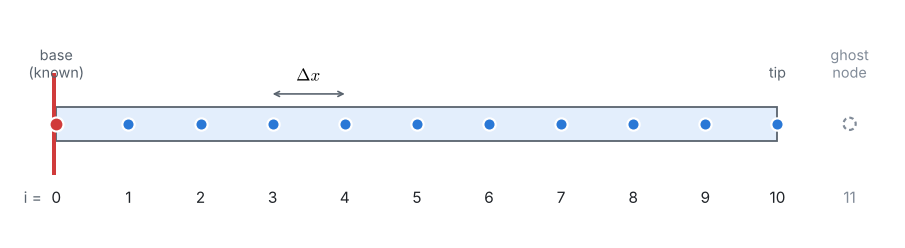

In [6]:
plots.grid(x, N)

The hollow circle to the right of the tip is a **ghost node**: an imaginary node outside the fin that will help us apply the insulated-tip condition in Pillar 4.

---
## Pillar 3 · Physics: the governing equation

Take a thin slice of the fin, between $x$ and $x + dx$, and write an **energy balance** for it. In steady state, nothing is stored, so

$$\underbrace{q_x}_{\text{conducted in}} \;=\; \underbrace{q_{x+dx}}_{\text{conducted out}} \;+\; \underbrace{h\,(P\,dx)\,(T - T_\infty)}_{\text{convected to the air}}$$

With Fourier's law, $q_x = -k A_c\, \dfrac{dT}{dx}$, and $q_{x+dx} = q_x + \dfrac{dq_x}{dx}dx$, this becomes the **fin equation**

$$k A_c \frac{d^2T}{dx^2} - h P\,(T - T_\infty) = 0
\qquad\Longleftrightarrow\qquad
\frac{d^2T}{dx^2} - m^2\,(T - T_\infty) = 0,
\qquad m^2 = \frac{hP}{kA_c} = \frac{4h}{kd}.$$

It is a second-order ordinary differential equation, so it needs **two boundary conditions**:

* at the base: $T(0) = T_b$ (a *Dirichlet* condition, the value is known);
* at the insulated tip: no heat leaves, so $\dfrac{dT}{dx}\Big|_{x=L} = 0$ (a *Neumann* condition, the slope is known).

This simple case has an **exact solution**, which we will use to check our numerical answer:

$$\frac{T(x) - T_\infty}{T_b - T_\infty} = \frac{\cosh\big(m\,(L - x)\big)}{\cosh(mL)}.$$

In [7]:
m = math.sqrt(h * P / (k * A_c))          # fin parameter [1/m]


def T_exact(xx):
    """Exact temperature [°C] at position xx [m] (used only to check the FDM)."""
    return T_inf + (T_b - T_inf) * math.cosh(m * (L - xx)) / math.cosh(m * L)


print(f"m = {m:.4f} 1/m,   mL = {m * L:.4f}")
print(f"exact tip temperature T(L) = {T_exact(L):.3f} °C")

m = 9.1863 1/m,   mL = 0.9186
exact tip temperature T(L) = 78.194 °C


---
## Pillar 4 · Numerical scheme: from the differential equation to algebraic equations

At an interior node $i$ we replace the second derivative by the **central difference** (from Taylor series, error $\mathcal{O}(\Delta x^2)$):

$$\frac{d^2T}{dx^2}\bigg|_i \approx \frac{T_{i-1} - 2T_i + T_{i+1}}{\Delta x^2}.$$

Putting it into the fin equation and multiplying by $\Delta x^2$:

$$T_{i-1} - (2 + \beta)\,T_i + T_{i+1} = -\beta\, T_\infty, \qquad \beta = m^2 \Delta x^2. \qquad (i = 1,\dots,N-1)$$

**Base node** $i = 0$: the temperature is known, $T_0 = T_b$.

**Tip node** $i = N$: the same interior equation would need $T_{N+1}$, a node outside the fin. The insulated tip gives it to us: a central difference of the slope at the tip is

$$\frac{dT}{dx}\bigg|_N \approx \frac{T_{N+1} - T_{N-1}}{2\Delta x} = 0 \quad\Longrightarrow\quad T_{N+1} = T_{N-1}.$$

The **ghost node** simply mirrors node $N-1$. Substituting it into the interior equation:

$$2\,T_{N-1} - (2 + \beta)\,T_N = -\beta\, T_\infty.$$

We now have $N+1$ linear equations for the $N+1$ unknown temperatures. Every equation has the same shape,

$$a_i\,T_{i-1} + b_i\,T_i + c_i\,T_{i+1} = r_i,$$

so we store the system as four lists of coefficients $a$, $b$, $c$ and $r$. Because each equation only involves a node and its two neighbours, the system is **tridiagonal**.

In [8]:
def build_system(N):
    """Coefficients a, b, c, r of the FDM equations for a grid with N intervals."""
    dx = L / N
    beta = (m * dx) ** 2

    a = [0.0] * (N + 1)   # coefficient of T[i-1]
    b = [0.0] * (N + 1)   # coefficient of T[i]
    c = [0.0] * (N + 1)   # coefficient of T[i+1]
    r = [0.0] * (N + 1)   # right-hand side

    # node 0, the base: T[0] = T_b
    b[0] = 1.0
    r[0] = T_b

    # interior nodes: T[i-1] - (2 + beta) T[i] + T[i+1] = -beta T_inf
    for i in range(1, N):
        a[i] = 1.0
        b[i] = -(2.0 + beta)
        c[i] = 1.0
        r[i] = -beta * T_inf

    # node N, the insulated tip (ghost node T[N+1] = T[N-1]):
    # 2 T[N-1] - (2 + beta) T[N] = -beta T_inf
    a[N] = 2.0
    b[N] = -(2.0 + beta)
    r[N] = -beta * T_inf

    return a, b, c, r

Let us build the system for our grid and print every equation, exactly as you would write it by hand:

In [9]:
a, b, c, r = build_system(N)
print(f"beta = (m dx)^2 = {(m * dx) ** 2:.5f}\n")

for i in range(N + 1):
    terms = []
    if a[i] != 0:
        terms.append(f"{a[i]:+.0f}·T{i - 1}")
    terms.append(f"{b[i]:+.5f}·T{i}")
    if c[i] != 0:
        terms.append(f"{c[i]:+.0f}·T{i + 1}")
    print(f"node {i:2d}:  {'  '.join(terms):40s} = {r[i]:9.4f}")

beta = (m dx)^2 = 0.00844

node  0:  +1.00000·T0                              =  100.0000
node  1:  +1·T0  -2.00844·T1  +1·T2                =   -0.2532
node  2:  +1·T1  -2.00844·T2  +1·T3                =   -0.2532
node  3:  +1·T2  -2.00844·T3  +1·T4                =   -0.2532
node  4:  +1·T3  -2.00844·T4  +1·T5                =   -0.2532
node  5:  +1·T4  -2.00844·T5  +1·T6                =   -0.2532
node  6:  +1·T5  -2.00844·T6  +1·T7                =   -0.2532
node  7:  +1·T6  -2.00844·T7  +1·T8                =   -0.2532
node  8:  +1·T7  -2.00844·T8  +1·T9                =   -0.2532
node  9:  +1·T8  -2.00844·T9  +1·T10               =   -0.2532
node 10:  +2·T9  -2.00844·T10                      =   -0.2532


---
## Pillar 5 · Solution setup: how do we solve the equations?

We solve the same system with two different algorithms, to see the pros and cons of each.

### A · Gauss–Seidel iteration (iterative)

Solve each equation for its own node,

$$T_i = \frac{r_i - a_i\,T_{i-1} - c_i\,T_{i+1}}{b_i},$$

and sweep through the nodes again and again, always using the **newest** values available. We start from the **initial condition** of the problem: the whole fin at 30 °C (except the base, held at 100 °C). Each sweep lets the heat creep a little further along the fin, so the iterations look like the fin slowly warming up. We stop when the largest change during a sweep is below a **tolerance**.

### B · Thomas algorithm (direct)

A shortcut of Gaussian elimination for tridiagonal systems: one **forward sweep** eliminates $T_{i-1}$ from every equation, then **back substitution** gives the temperatures from the tip back to the base. No iterations, no tolerance, and only $\mathcal{O}(N)$ operations.

| | Gauss–Seidel | Thomas algorithm |
|---|---|---|
| type | iterative | direct |
| idea | improve a guess sweep by sweep | eliminate, then back-substitute |
| needs | an initial guess and a tolerance | a tridiagonal system |
| 👍 | very simple, works in 2D and 3D too | exact (up to round-off) in a single pass, very fast |
| 👎 | can need many sweeps on fine grids | only for tridiagonal (1D) systems |

In [10]:
def gauss_seidel(a, b, c, r, T_start, tol=1e-6, max_sweeps=10_000):
    """Solve a_i T[i-1] + b_i T[i] + c_i T[i+1] = r_i by Gauss-Seidel iteration."""
    T = T_start[:]                 # work on a copy of the initial guess
    n = len(T)
    history = [T[:]]               # temperatures after every sweep (for plotting)
    changes = []                   # largest change in every sweep

    for sweep in range(max_sweeps):
        largest_change = 0.0
        for i in range(n):
            left = a[i] * T[i - 1] if i > 0 else 0.0
            right = c[i] * T[i + 1] if i < n - 1 else 0.0
            new_value = (r[i] - left - right) / b[i]
            largest_change = max(largest_change, abs(new_value - T[i]))
            T[i] = new_value       # use the new value immediately
        history.append(T[:])
        changes.append(largest_change)
        if largest_change < tol:   # converged
            break

    return T, history, changes

In [11]:
def thomas(a, b, c, r):
    """Solve a tridiagonal system directly (Thomas algorithm)."""
    n = len(b)
    c_star = [0.0] * n
    r_star = [0.0] * n

    # forward sweep: remove T[i-1] from every equation
    c_star[0] = c[0] / b[0]
    r_star[0] = r[0] / b[0]
    for i in range(1, n):
        denominator = b[i] - a[i] * c_star[i - 1]
        c_star[i] = c[i] / denominator
        r_star[i] = (r[i] - a[i] * r_star[i - 1]) / denominator

    # back substitution: from the tip back to the base
    T = [0.0] * n
    T[n - 1] = r_star[n - 1]
    for i in range(n - 2, -1, -1):
        T[i] = r_star[i] - c_star[i] * T[i + 1]

    return T

---
## Pillar 6 · Compute

Start Gauss–Seidel from the initial condition and solve the same system with the Thomas algorithm.

In [12]:
tol = 1e-6                         # stop when no temperature changes by more than 1e-6 °C

T_start = [T_init] * (N + 1)       # initial condition: the whole fin at 30 °C ...
T_start[0] = T_b                   # ... except the base, which is held at 100 °C

T_gs, history, changes = gauss_seidel(a, b, c, r, T_start, tol)
T_th = thomas(a, b, c, r)

print(f"Gauss-Seidel converged after {len(changes)} sweeps")
print(f"largest difference between the two methods: {max(abs(p - q) for p, q in zip(T_gs, T_th)):.1e} °C")

Gauss-Seidel converged after 437 sweeps
largest difference between the two methods: 2.9e-05 °C


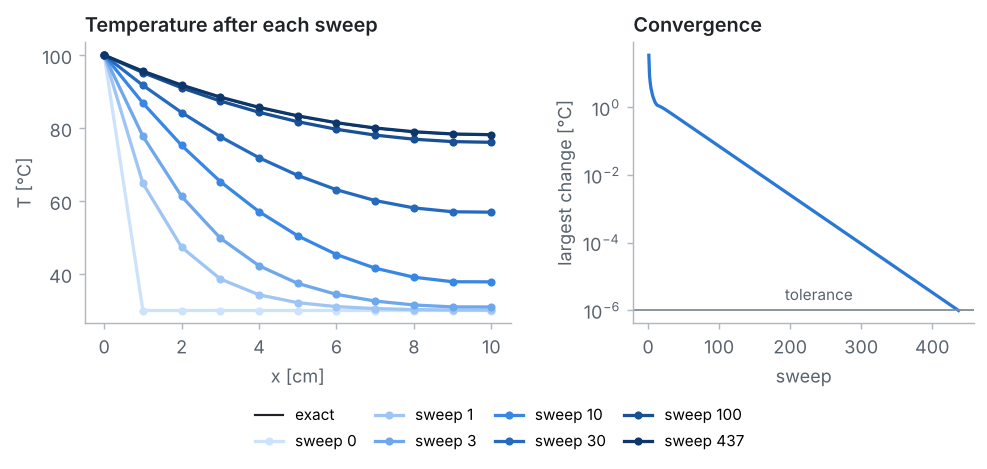

In [13]:
plots.sweeps(x, history, changes, T_exact, tol)

On the left, each curve is the temperature after one more Gauss–Seidel sweep: starting from 30 °C, heat spreads from the base towards the tip until the profile stops changing. On the right, the largest change per sweep falls steadily until it drops below the tolerance.

> **Why such a small tolerance?** Gauss–Seidel creeps towards the answer in small steps, so "the last sweep changed nothing by more than 0.0001 °C" does *not* mean "the answer is within 0.0001 °C". With `tol = 1e-4` the two methods still differ by about 0.003 °C; try it! A tight tolerance makes the iterative answer match the direct one.

Now compare both solutions with the exact solution, node by node:

In [14]:
print(" node   x [cm]   Gauss-Seidel   Thomas    exact     error")
for i in range(N + 1):
    exact = T_exact(x[i])
    print(f"{i:4d}   {x[i] * 100:5.1f}    {T_gs[i]:9.4f}   {T_th[i]:9.4f}  {exact:8.4f}  {T_th[i] - exact:+.4f}")

 node   x [cm]   Gauss-Seidel   Thomas    exact     error
   0     0.0     100.0000    100.0000  100.0000  +0.0000
   1     1.0      95.6278     95.6278   95.6254  +0.0024
   2     2.0      91.8094     91.8094   91.8049  +0.0045
   3     3.0      88.5126     88.5126   88.5064  +0.0062
   4     4.0      85.7095     85.7095   85.7019  +0.0076
   5     5.0      83.3766     83.3766   83.3678  +0.0088
   6     6.0      81.4941     81.4942   81.4845  +0.0097
   7     7.0      80.0462     80.0463   80.0358  +0.0104
   8     8.0      79.0206     79.0207   79.0098  +0.0109
   9     9.0      78.4087     78.4088   78.3976  +0.0112
  10    10.0      78.2053     78.2054   78.1941  +0.0113


---
## Pillar 7 · Post-processing: plots, quantities of interest and verification

### The temperature distribution

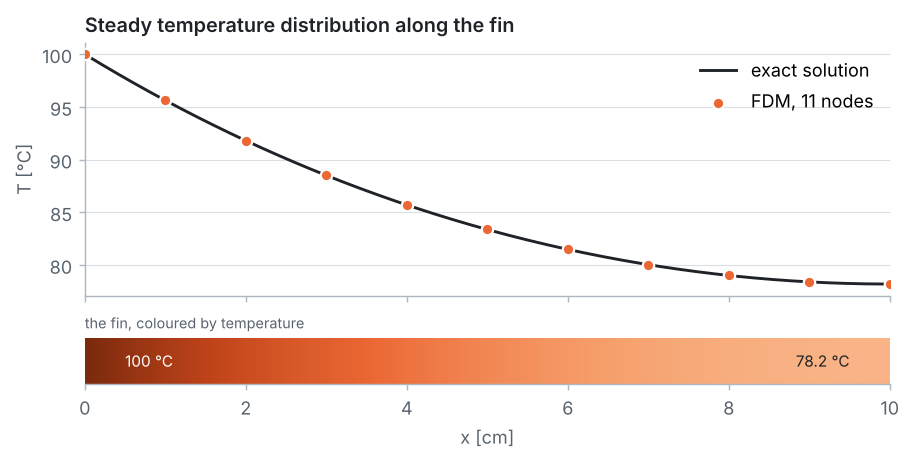

In [15]:
plots.profile(x, T_th, T_exact, T_inf, T_b)

### Quantities of interest: tip temperature and heat loss

An engineer usually wants a few numbers rather than a whole curve. Here: the **tip temperature** and the **heat removed by the fin**, $q_{fin}$.

In steady state, all the heat entering at the base leaves through the fin surface by convection, so we add up the convection from every segment (each node represents a segment $\Delta x$ long; the end nodes represent only half a segment, the *trapezoidal rule*):

$$q_{fin} \approx h P \,\Delta x \left[\tfrac{1}{2}(T_0 - T_\infty) + \sum_{i=1}^{N-1}(T_i - T_\infty) + \tfrac{1}{2}(T_N - T_\infty)\right].$$

The exact value is $q_{fin} = \sqrt{hPkA_c}\,(T_b - T_\infty)\tanh(mL)$.

In [16]:
q_fdm = 0.5 * (T_th[0] - T_inf) + 0.5 * (T_th[N] - T_inf)
for i in range(1, N):
    q_fdm += T_th[i] - T_inf
q_fdm *= h * P * dx

q_exact = math.sqrt(h * P * k * A_c) * (T_b - T_inf) * math.tanh(m * L)

print(f"tip temperature :  FDM {T_th[N]:8.3f} °C    exact {T_exact(L):8.3f} °C")
print(f"heat loss q_fin :  FDM {q_fdm:8.4f} W     exact {q_exact:8.4f} W"
      f"    ({100 * (q_fdm - q_exact) / q_exact:+.2f} %)")

tip temperature :  FDM   78.205 °C    exact   78.194 °C
heat loss q_fin :  FDM   2.1721 W     exact   2.1702 W    (+0.08 %)


### Verification: is the grid fine enough?

The central difference is **second-order accurate**: halving $\Delta x$ should divide the error by about 4. We check this by solving the problem on finer and finer grids, re-using `build_system` and `thomas`:

In [17]:
dxs, errors = [], []
print("    N    dx [cm]   largest error [°C]   ratio")
for n_int in (5, 10, 20, 40, 80):
    a_n, b_n, c_n, r_n = build_system(n_int)
    T_n = thomas(a_n, b_n, c_n, r_n)
    error = max(abs(T_n[i] - T_exact(i * L / n_int)) for i in range(n_int + 1))
    ratio = f"{errors[-1] / error:5.2f}" if errors else ""
    dxs.append(L / n_int)
    errors.append(error)
    print(f"{n_int:5d}   {100 * L / n_int:7.3f}   {error:14.6f}      {ratio}")

    N    dx [cm]   largest error [°C]   ratio
    5     2.000         0.044991      
   10     1.000         0.011279       3.99
   20     0.500         0.002822       4.00
   40     0.250         0.000706       4.00
   80     0.125         0.000176       4.00


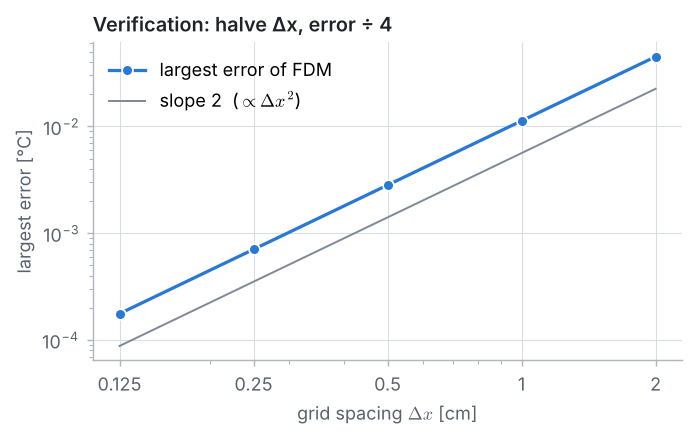

In [18]:
plots.convergence(dxs, errors)

The error drops by a factor of about 4 every time the grid spacing is halved, exactly as expected for a second-order scheme. With 10 intervals the largest error is already only a few hundredths of a degree, so our grid is fine enough.

---
## Summary

* The fin equation $T'' - m^2(T - T_\infty) = 0$ was turned into **one algebraic equation per node** with a central difference.
* The **insulated tip** was handled with a **ghost node**, $T_{N+1} = T_{N-1}$.
* **Gauss–Seidel** (starting from the initial 30 °C) and the **Thomas algorithm** give the same temperatures; Thomas does it in one pass.
* The FDM solution agrees with the exact solution, and the error shrinks like $\Delta x^2$.

## Try it yourself

1. Change `h` to 100 W/(m²·K) (forced air cooling). How do the tip temperature and $q_{fin}$ change?
2. Replace aluminium by stainless steel ($k \approx 15$ W/(m·K)). Why does the tip get so much colder?
3. Start Gauss–Seidel from a different initial guess, e.g. 100 °C everywhere. Does the final answer change? Does the number of sweeps?
4. Change the Gauss–Seidel update to a **Jacobi** update (use only values from the previous sweep). How many more sweeps does it need?
5. *Challenge:* replace the insulated tip by a convective tip, $-k\,dT/dx = h\,(T_N - T_\infty)$. Which equation in `build_system` changes?